In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Utility functions
from utils import evaluate_model, plot_confusion_matrix, plot_roc_curves, compare_models

sns.set_theme(style="whitegrid")
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("data/titanic_cleaned.csv")
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
0,0,3,0,22.0,1,0,7.2500,0,2,0,...,1,0,0,0,1,0,0,0,0,0
1,1,1,1,38.0,1,0,71.2833,1,2,0,...,0,1,0,0,0,1,0,0,0,1
2,1,3,1,26.0,0,0,7.9250,0,1,1,...,0,0,0,0,1,0,0,1,0,0
3,1,1,1,35.0,1,0,53.1000,1,2,0,...,0,1,0,0,1,0,0,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,1,1,...,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,27.0,0,0,13.0000,0,1,1,...,0,0,1,0,1,0,0,1,0,0
887,1,1,1,19.0,0,0,30.0000,1,1,1,...,0,0,0,0,1,0,0,0,1,0
888,0,3,1,21.5,1,2,23.4500,0,4,0,...,0,0,0,0,1,0,0,0,1,0
889,1,1,0,26.0,0,0,30.0000,1,1,1,...,1,0,0,0,1,0,0,0,1,0


## Features and Target

In [3]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"\nFeature columns: {X.columns.tolist()}")


Features shape: (891, 22)
Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Feature columns: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'AgeGroup_Teen', 'AgeGroup_Young Adult', 'AgeGroup_Adult', 'AgeGroup_Senior', 'FareBin_Medium', 'FareBin_High', 'FareBin_Very High']


In [4]:
from sklearn.model_selection import train_test_split

In [5]:
# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,# stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nTraining survival rate: {y_train.mean():.2%}")
print(f"Test survival rate: {y_test.mean():.2%}")

Training set: 712 samples
Test set: 179 samples

Training survival rate: 37.78%
Test survival rate: 40.78%


In [6]:
# Feature scaling — for KNN, SVM, and Logistic Regression
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Scaling complete. First 3 rows of scaled training data:")
X_train_scaled.head(3)

Scaling complete. First 3 rows of scaled training data:


,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_Q,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
33,-0.383302,-0.740153,2.785777,-0.480505,-0.470152,-0.437685,-0.536211,-0.564906,0.809823,-0.289333,...,0.858246,-0.406574,-0.178561,-0.292174,-1.182077,-0.560047,6.595453,1.706484,-0.579513,-0.568700
185,-1.590873,-0.740153,0.822154,-0.480505,-0.470152,0.390519,1.864936,-0.564906,0.809823,-0.289333,...,0.858246,-0.406574,-0.178561,-0.292174,-1.182077,1.785563,-0.151620,-0.586000,-0.579513,1.758395
668,0.824269,-0.740153,1.048726,-0.480505,-0.470152,-0.489054,-0.536211,-0.564906,0.809823,-0.289333,...,0.858246,-0.406574,-0.178561,-0.292174,-1.182077,1.785563,-0.151620,1.706484,-0.579513,-0.568700


# Model Training

In [7]:
# Store results for comparison
results = []
trained_models = {}

## Logistic Regression

In [8]:
from sklearn.linear_model import LogisticRegression


  Logistic Regression Results
  Accuracy:  0.8436
  Precision: 0.8571
  Recall:    0.7397
  F1 Score:  0.7941

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.92      0.87       106
           1       0.86      0.74      0.79        73

    accuracy                           0.84       179
   macro avg       0.85      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



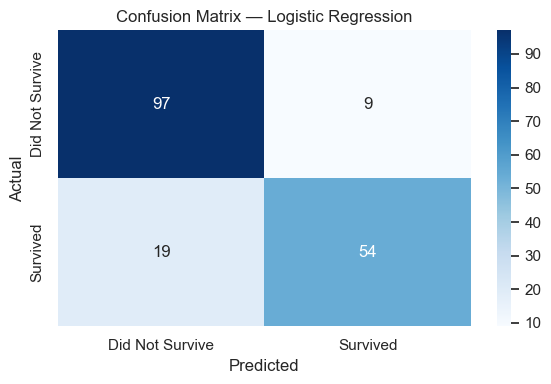

In [9]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
metrics_lr = evaluate_model(y_test, y_pred_lr, "Logistic Regression")
results.append(metrics_lr)
trained_models["Logistic Regression"] = lr

plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression")


## Decision Tree


  Decision Tree Results
  Accuracy:  0.8380
  Precision: 0.8548
  Recall:    0.7260
  F1 Score:  0.7852

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87       106
           1       0.85      0.73      0.79        73

    accuracy                           0.84       179
   macro avg       0.84      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



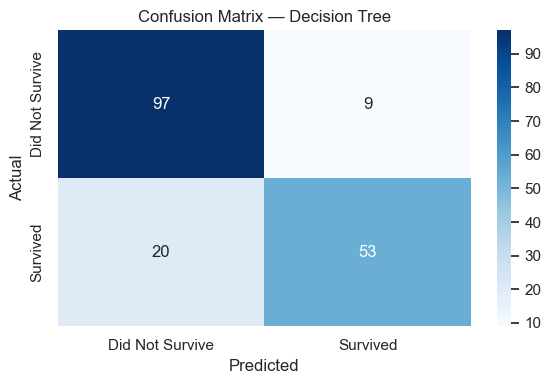

In [10]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
metrics_dt = evaluate_model(y_test, y_pred_dt, "Decision Tree")
results.append(metrics_dt)
trained_models["Decision Tree"] = dt

plot_confusion_matrix(y_test, y_pred_dt, "Decision Tree")


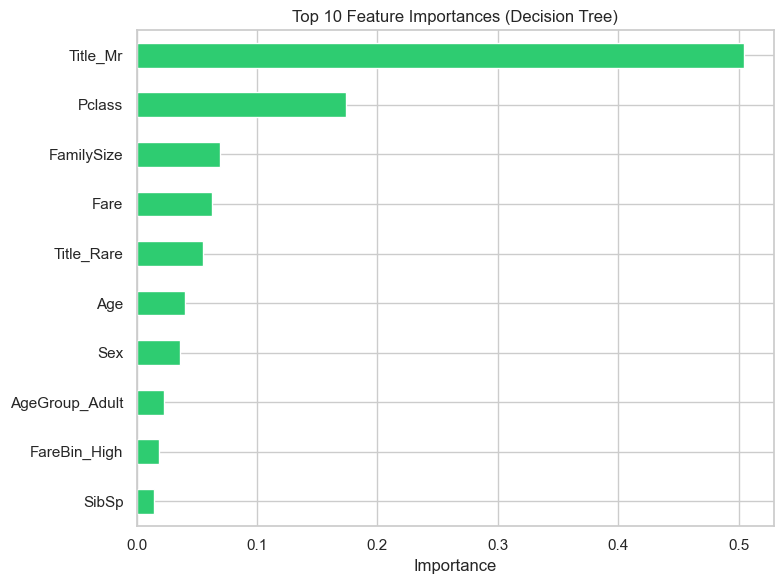

In [11]:
# Feature importance from Decision Tree
feature_imp = pd.Series(dt.feature_importances_, index=X_train.columns)
feature_imp = feature_imp.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp.tail(10).plot(kind="barh", ax=ax, color="#2ecc71")
ax.set_title("Top 10 Feature Importances (Decision Tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## Random Forest


  Random Forest Results
  Accuracy:  0.8492
  Precision: 0.8966
  Recall:    0.7123
  F1 Score:  0.7939

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88       106
           1       0.90      0.71      0.79        73

    accuracy                           0.85       179
   macro avg       0.86      0.83      0.84       179
weighted avg       0.86      0.85      0.85       179



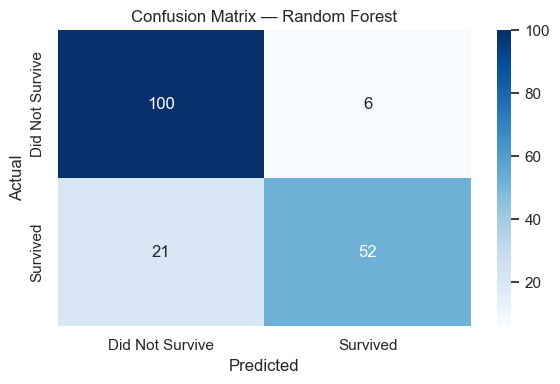

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=7)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
metrics_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
results.append(metrics_rf)
trained_models["Random Forest"] = rf

plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")


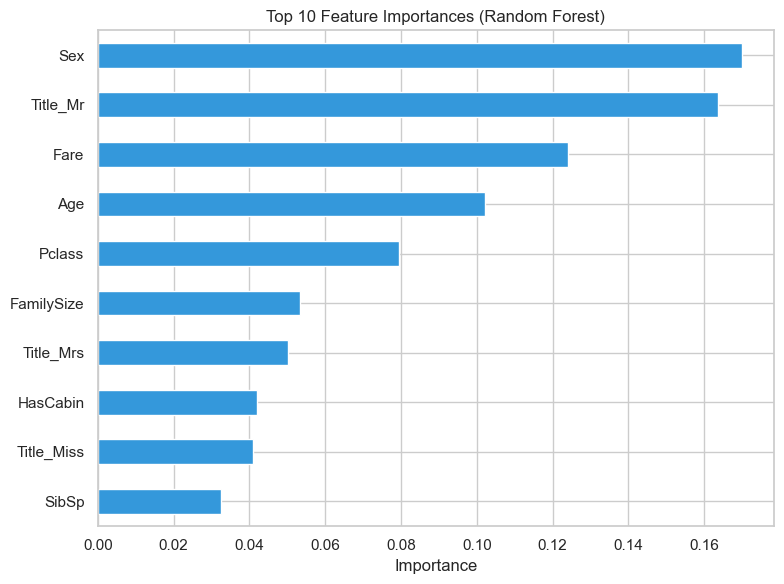

In [13]:
# Feature importance from Random Forest
feature_imp_rf = pd.Series(rf.feature_importances_, index=X_train.columns)
feature_imp_rf = feature_imp_rf.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp_rf.tail(10).plot(kind="barh", ax=ax, color="#3498db")
ax.set_title("Top 10 Feature Importances (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


## KNN


  K-Nearest Neighbors Results
  Accuracy:  0.8156
  Precision: 0.8125
  Recall:    0.7123
  F1 Score:  0.7591

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       106
           1       0.81      0.71      0.76        73

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.82      0.82      0.81       179



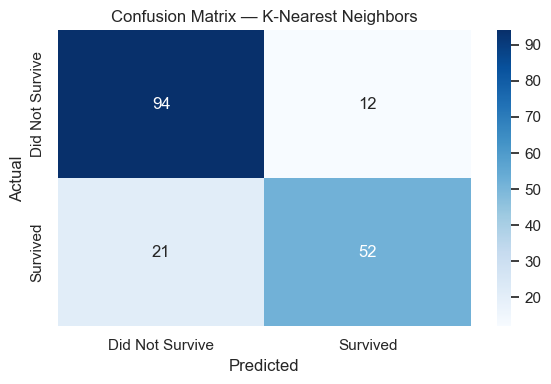

In [14]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
metrics_knn = evaluate_model(y_test, y_pred_knn, "K-Nearest Neighbors")
results.append(metrics_knn)
trained_models["K-Nearest Neighbors"] = knn

plot_confusion_matrix(y_test, y_pred_knn, "K-Nearest Neighbors")


In [15]:
from sklearn.model_selection import cross_val_score

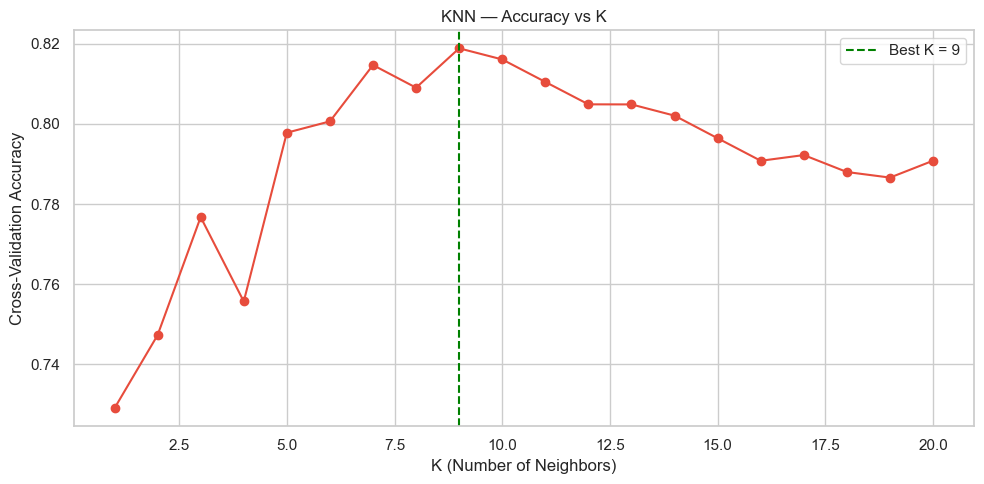

Best K: 9 with accuracy: 0.8189


In [16]:
# Find optimal K using cross-validation
k_range = range(1, 21)
k_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy")
    k_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, k_scores, marker="o", color="#e74c3c")
ax.set_title("KNN — Accuracy vs K")
ax.set_xlabel("K (Number of Neighbors)")
ax.set_ylabel("Cross-Validation Accuracy")
best_k = list(k_range)[np.argmax(k_scores)]
ax.axvline(x=best_k, color="green", linestyle="--", label=f"Best K = {best_k}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Best K: {best_k} with accuracy: {max(k_scores):.4f}")


## SVM


  SVM Results
  Accuracy:  0.8492
  Precision: 0.8833
  Recall:    0.7260
  F1 Score:  0.7970

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.93      0.88       106
           1       0.88      0.73      0.80        73

    accuracy                           0.85       179
   macro avg       0.86      0.83      0.84       179
weighted avg       0.85      0.85      0.85       179



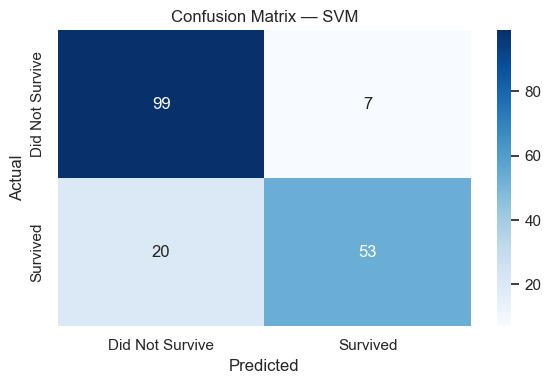

In [17]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
metrics_svm = evaluate_model(y_test, y_pred_svm, "SVM")
results.append(metrics_svm)
trained_models["SVM"] = svm

plot_confusion_matrix(y_test, y_pred_svm, "SVM")


## Gradient Boosting


  Gradient Boosting Results
  Accuracy:  0.8380
  Precision: 0.8548
  Recall:    0.7260
  F1 Score:  0.7852

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87       106
           1       0.85      0.73      0.79        73

    accuracy                           0.84       179
   macro avg       0.84      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



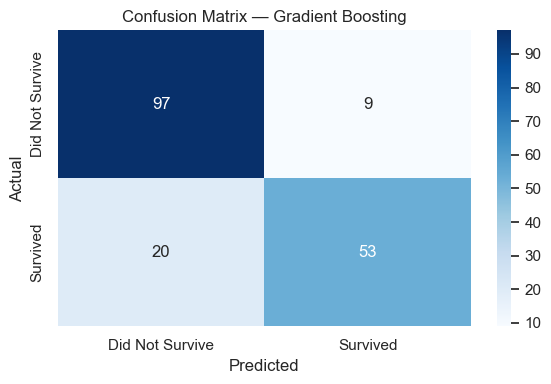

In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
metrics_gb = evaluate_model(y_test, y_pred_gb, "Gradient Boosting")
results.append(metrics_gb)
trained_models["Gradient Boosting"] = gb

plot_confusion_matrix(y_test, y_pred_gb, "Gradient Boosting")


## Gaussian Naive Bayes


  Naive Bayes Results
  Accuracy:  0.8212
  Precision: 0.7887
  Recall:    0.7671
  F1 Score:  0.7778

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       106
           1       0.79      0.77      0.78        73

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



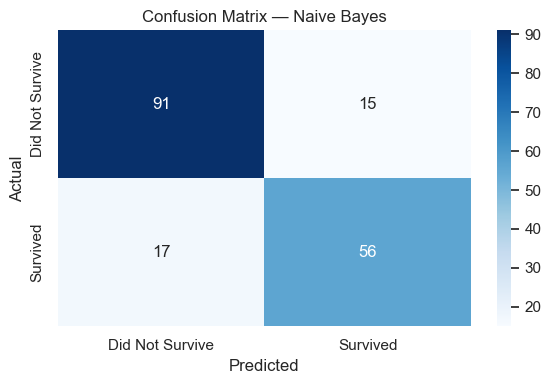

In [19]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
metrics_nb = evaluate_model(y_test, y_pred_nb, "Naive Bayes")
results.append(metrics_nb)
trained_models["Naive Bayes"] = nb

plot_confusion_matrix(y_test, y_pred_nb, "Naive Bayes")


# Model Comparison

In [20]:
# Compare all models
comparison_df = compare_models(results)
comparison_df.style.background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1 Score"])


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.849162,0.883333,0.726027,0.796992
1,Logistic Regression,0.843575,0.857143,0.739726,0.794118
2,Random Forest,0.849162,0.896552,0.712329,0.793893
3,Decision Tree,0.837989,0.854839,0.726027,0.785185
4,Gradient Boosting,0.837989,0.854839,0.726027,0.785185
5,Naive Bayes,0.821229,0.788732,0.767123,0.777778
6,K-Nearest Neighbors,0.815642,0.812500,0.712329,0.759124


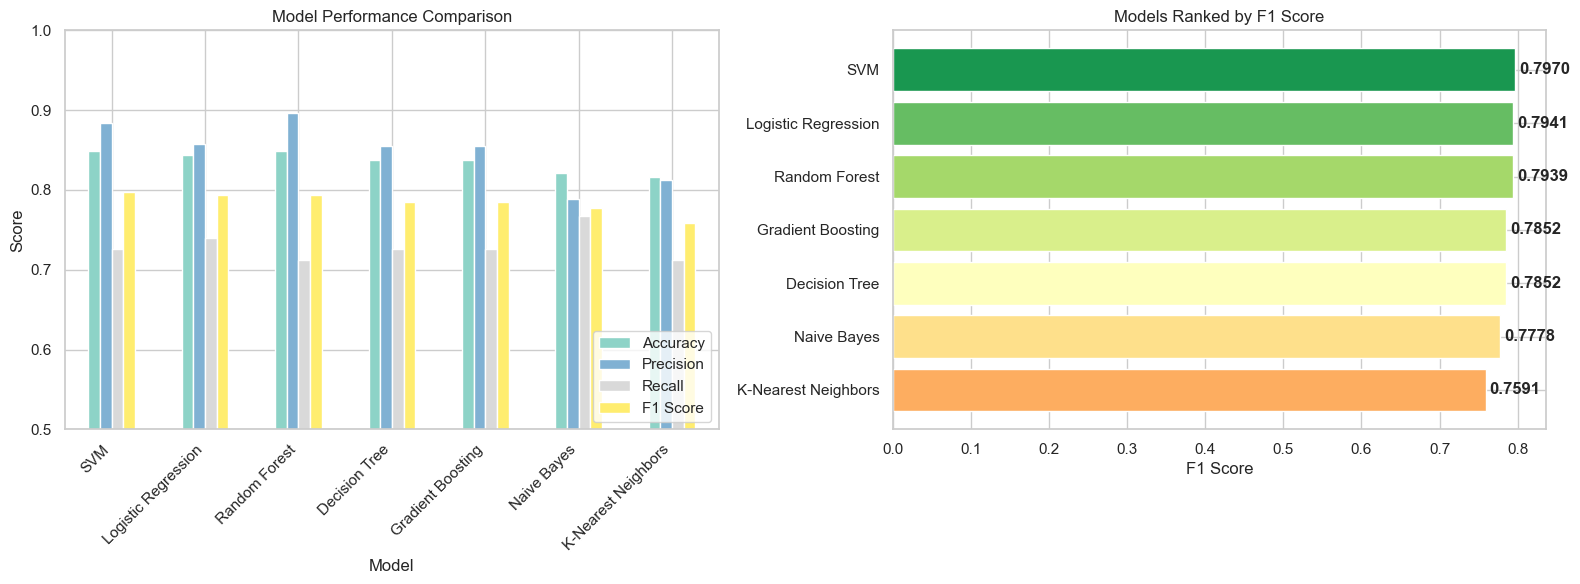

In [21]:
# Visualize model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of all metrics
comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", ax=axes[0], colormap="Set3"
)
axes[0].set_title("Model Performance Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.5, 1.0)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].legend(loc="lower right")

# F1 Score ranking
sorted_df = comparison_df.sort_values("F1 Score", ascending=True)
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(sorted_df)))
axes[1].barh(sorted_df["Model"], sorted_df["F1 Score"], color=colors)
axes[1].set_title("Models Ranked by F1 Score")
axes[1].set_xlabel("F1 Score")
for i, v in enumerate(sorted_df["F1 Score"]):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center", fontweight="bold")

plt.tight_layout()
plt.show()


In [22]:
# Cross-validation for all models (5-fold)
cv_results = {}

models_for_cv = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, max_depth=7),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=3),
    "Naive Bayes": GaussianNB(),
}

print("5-Fold Cross-Validation Results:")
print("=" * 55)
for name, model in models_for_cv.items():
    # Use scaled data for models that need it
    if name in ["Logistic Regression", "KNN", "SVM", "Naive Bayes"]:
        scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy")
    else:
        scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_results[name] = scores
    print(f"{name:25s} — Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")


5-Fold Cross-Validation Results:
Logistic Regression       — Mean: 0.8316 (+/- 0.0388)
Decision Tree             — Mean: 0.8161 (+/- 0.0354)
Random Forest             — Mean: 0.8245 (+/- 0.0374)
KNN                       — Mean: 0.7978 (+/- 0.0314)
SVM                       — Mean: 0.8091 (+/- 0.0300)
Gradient Boosting         — Mean: 0.8357 (+/- 0.0241)
Naive Bayes               — Mean: 0.7669 (+/- 0.0168)


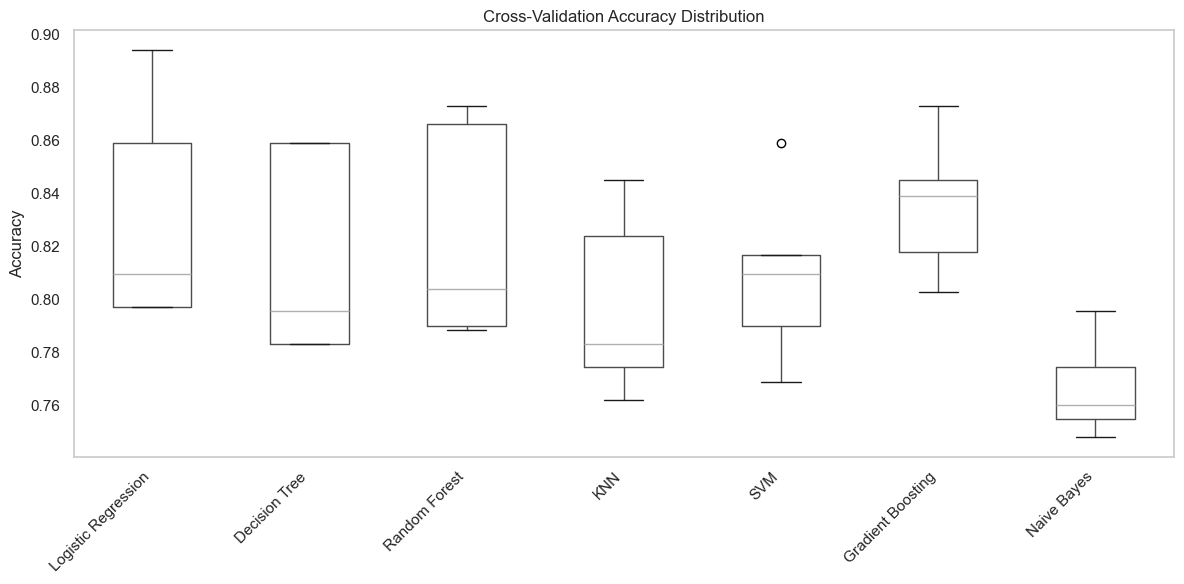

In [23]:
# Box plot of cross-validation scores
fig, ax = plt.subplots(figsize=(12, 6))
cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(ax=ax, grid=False)
ax.set_title("Cross-Validation Accuracy Distribution")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()


## ROC Curve

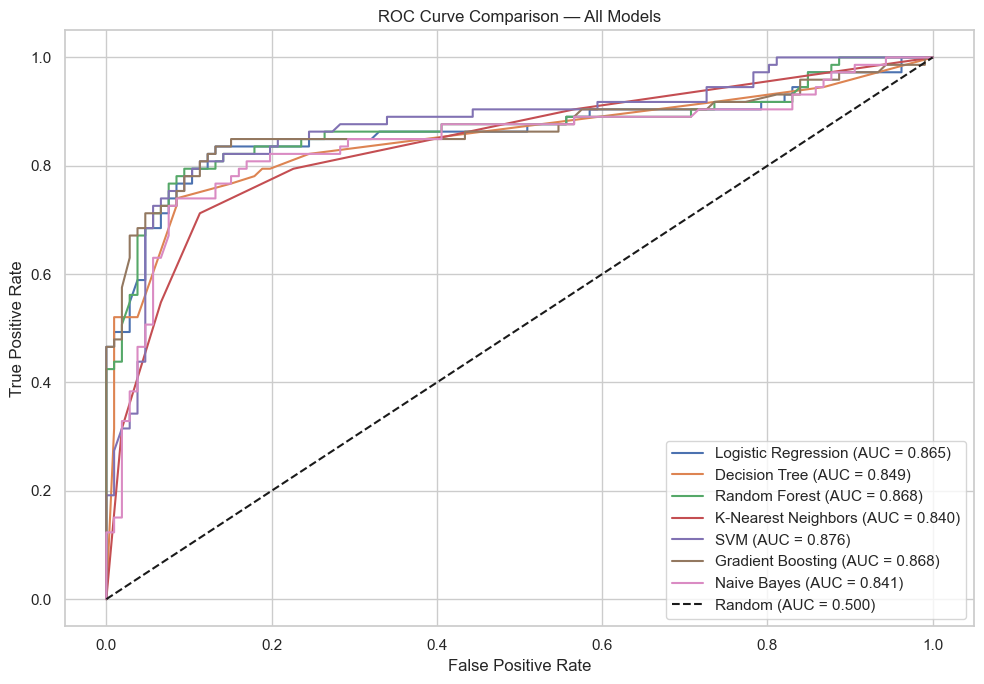

In [24]:
# Plot ROC curves for all models
# Note: KNN, SVM, LR, NB use scaled data; DT, RF, GB use unscaled
from sklearn.metrics import roc_curve,auc
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():
    # Choose the right test data
    if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM", "Naive Bayes"]:
        X_eval = X_test_scaled
    else:
        X_eval = X_test
    
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_eval)[:, 1]
    else:
        y_prob = model.decision_function(X_eval)
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — All Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Hyperparameter tuning

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [26]:
# hyperparameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best CV F1 score: {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best parameters: {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1 score: 0.7658



  Tuned Random Forest Results
  Accuracy:  0.8436
  Precision: 0.8947
  Recall:    0.6986
  F1 Score:  0.7846

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.94      0.88       106
           1       0.89      0.70      0.78        73

    accuracy                           0.84       179
   macro avg       0.86      0.82      0.83       179
weighted avg       0.85      0.84      0.84       179



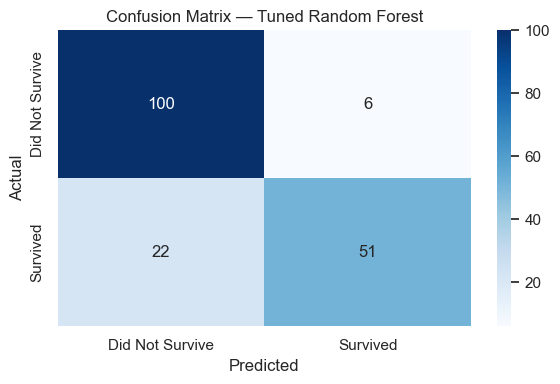

In [27]:
# tuned model
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

metrics_tuned = evaluate_model(y_test, y_pred_tuned, "Tuned Random Forest")
plot_confusion_matrix(y_test, y_pred_tuned, "Tuned Random Forest")


## Feature Importance

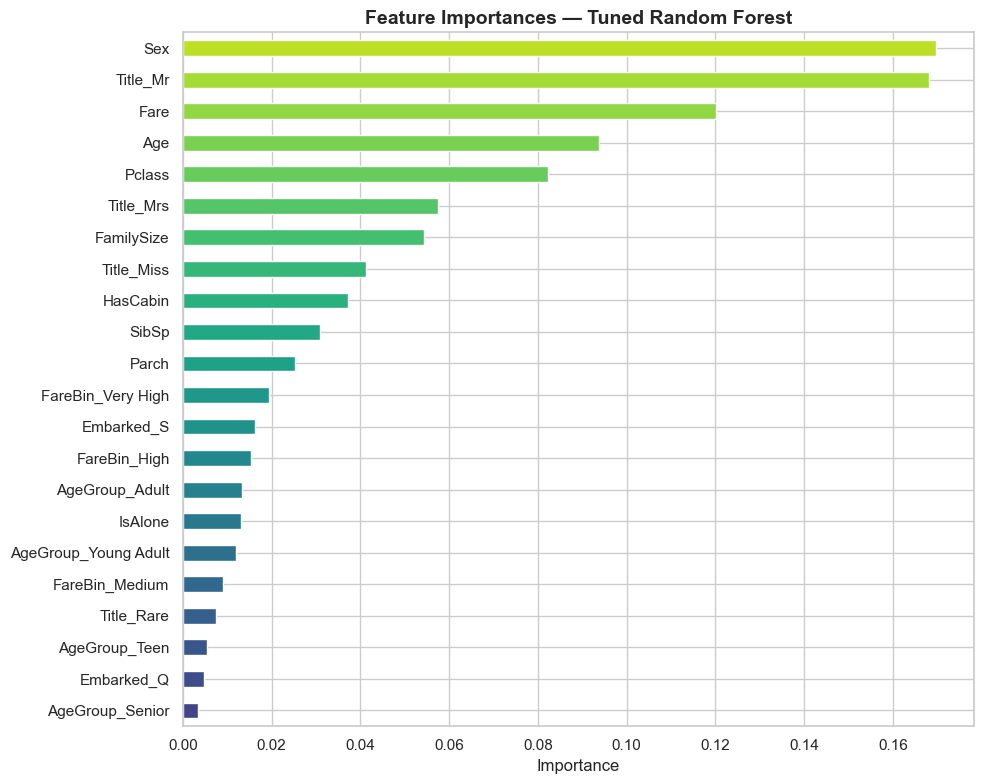


Top 5 most important features:
Pclass      0.082202
Age         0.093769
Fare        0.120123
Title_Mr    0.168213
Sex         0.169810
dtype: float64


In [28]:
# Feature importance from the tuned model
feature_imp_final = pd.Series(best_rf.feature_importances_, index=X_train.columns)
feature_imp_final = feature_imp_final.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(feature_imp_final)))
feature_imp_final.plot(kind="barh", ax=ax, color=colors)
ax.set_title("Feature Importances — Tuned Random Forest", fontsize=14, fontweight="bold")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nTop 5 most important features:")
print(feature_imp_final.tail(5))


# Prediction

In [29]:
# Example: Predict survival for a new passenger
# Create a sample with the same features as our training data
sample_passenger = pd.DataFrame([{
    col: 0 for col in X_train.columns
}])

# 25-year-old female in 1st class, traveling alone, fare $100, embarked at Cherbourg
sample_passenger["Pclass"] = 2
sample_passenger["Sex"] = 1  # female
sample_passenger["Age"] = 22
sample_passenger["Fare"] = 100
sample_passenger["FamilySize"] = 1
sample_passenger["IsAlone"] = 1
sample_passenger["HasCabin"] = 1

prediction = best_rf.predict(sample_passenger)[0]
probability = best_rf.predict_proba(sample_passenger)[0]

print("Sample Passenger: 25-year-old female, 1st class, solo traveler")
print(f"Prediction: {'Survived' if prediction == 1 else 'Did Not Survive'}")
print(f"Probability — Did Not Survive: {probability[0]:.2%}")
print(f"Probability — Survived: {probability[1]:.2%}")


Sample Passenger: 25-year-old female, 1st class, solo traveler
Prediction: Survived
Probability — Did Not Survive: 12.39%
Probability — Survived: 87.61%


# Summary
## Model Performance

In [30]:
# Final comparison including tuned model
all_results = results + [metrics_tuned]
final_df = compare_models(all_results)
final_df


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.849162,0.883333,0.726027,0.796992
1,Logistic Regression,0.843575,0.857143,0.739726,0.794118
2,Random Forest,0.849162,0.896552,0.712329,0.793893
3,Decision Tree,0.837989,0.854839,0.726027,0.785185
4,Gradient Boosting,0.837989,0.854839,0.726027,0.785185
5,Tuned Random Forest,0.843575,0.894737,0.698630,0.784615
6,Naive Bayes,0.821229,0.788732,0.767123,0.777778
7,K-Nearest Neighbors,0.815642,0.812500,0.712329,0.759124
